<a href="https://colab.research.google.com/github/lovkush7/MACHINE-LEARNING-/blob/main/KNN_passed_failed.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [6]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
path = "/content/drive/MyDrive/machinelearning/passed_failed.csv"

In [ ]:
import pandas as pd

In [ ]:
data = pd.read_csv(path)

In [ ]:
data.head()

,Age,StudyHours,Attendance,PreviousScore,SleepHours,Passed
0,56,1.3,92.7,63.8,6.5,1
1,46,4.0,80.0,60.2,7.7,1
2,32,2.8,89.1,82.1,6.9,1
3,60,8.1,82.2,73.4,9.0,1
4,25,5.0,76.5,83.3,7.8,1


In [7]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

In [8]:
data.shape

(200, 6)

In [9]:
data.describe()

,Age,StudyHours,Attendance,PreviousScore,SleepHours,Passed
count,200.000000,196.000000,196.000000,196.000000,200.000000,200.000000
mean,38.955000,5.283163,72.910204,65.898980,6.598500,0.905000
std,12.754858,2.796219,15.620069,16.650362,1.352997,0.293951
min,18.000000,0.500000,45.800000,35.200000,4.100000,0.000000
25%,27.750000,2.900000,59.300000,54.675000,5.500000,1.000000
50%,41.000000,5.100000,72.350000,67.100000,6.600000,1.000000
75%,50.000000,7.600000,85.975000,79.200000,7.800000,1.000000
max,60.000000,10.000000,99.800000,94.800000,9.000000,1.000000


In [10]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 6 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Age            200 non-null    int64  
 1   StudyHours     196 non-null    float64
 2   Attendance     196 non-null    float64
 3   PreviousScore  196 non-null    float64
 4   SleepHours     200 non-null    float64
 5   Passed         200 non-null    int64  
dtypes: float64(4), int64(2)
memory usage: 9.5 KB


In [11]:
data.isnull().sum()

,0
Age,0
StudyHours,4
Attendance,4
PreviousScore,4
SleepHours,0
Passed,0


In [12]:
data['StudyHours'] = data['StudyHours'].fillna(data['StudyHours'].mean())

In [13]:
data['Attendance'] = data['Attendance'].fillna(data['Attendance'].mean())

In [14]:
data['PreviousScore'] = data['PreviousScore'].fillna(data['PreviousScore'].mean())

In [15]:
data.isnull().sum()

,0
Age,0
StudyHours,0
Attendance,0
PreviousScore,0
SleepHours,0
Passed,0


In [16]:
data.duplicated().sum()

np.int64(0)

In [17]:
data['Passed'].value_counts()

,count
Passed,
1,181
0,19


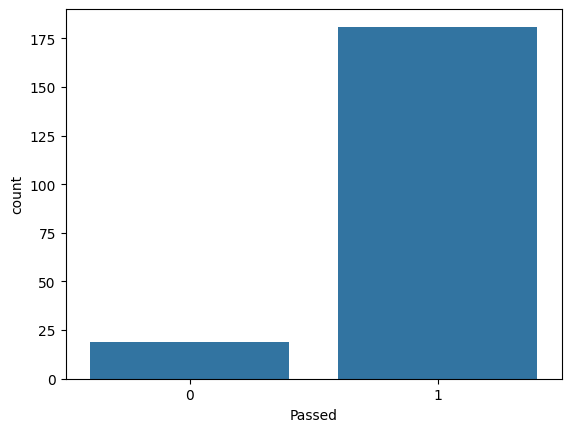

In [18]:
sns.countplot(x = 'Passed', data = data)
plt.show()

In [19]:
num_col = data.select_dtypes(include="number").columns

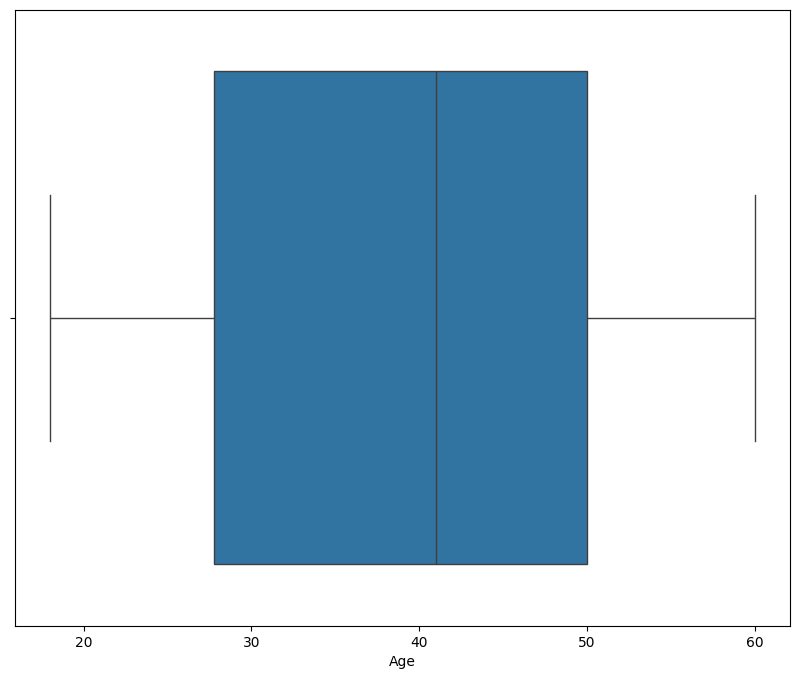

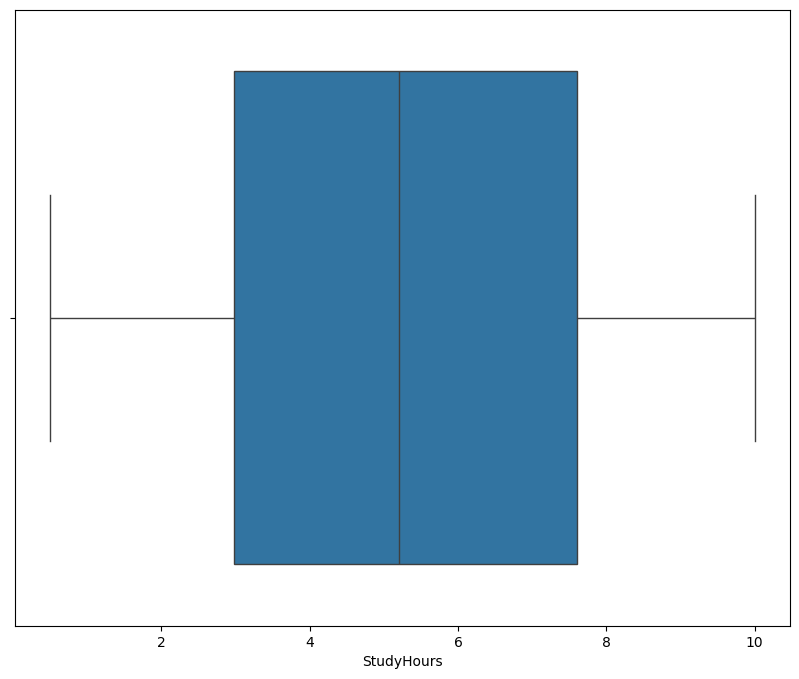

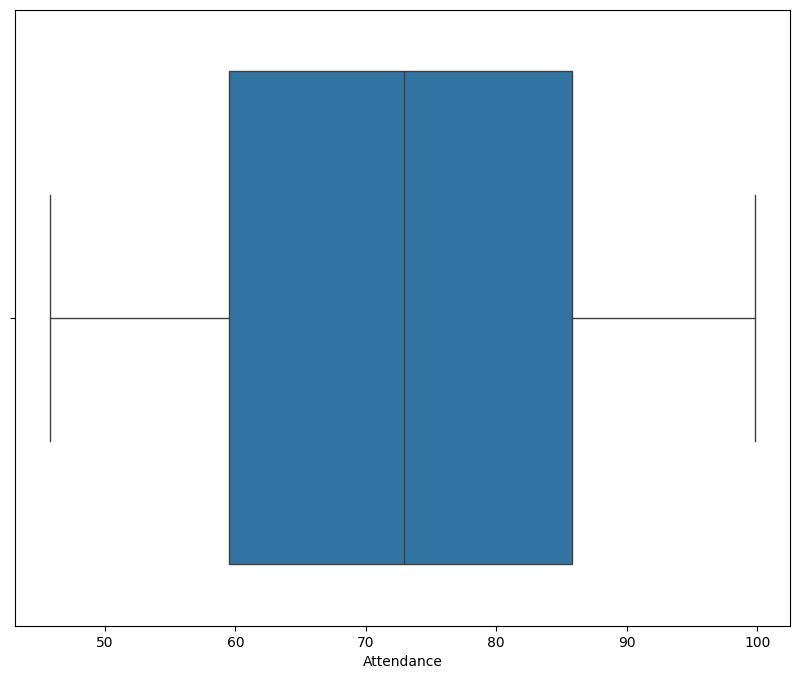

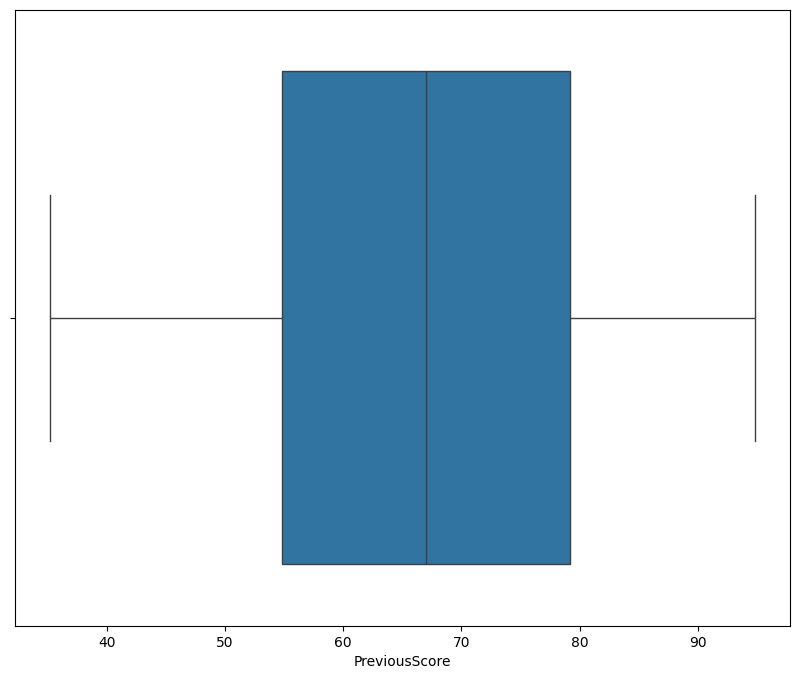

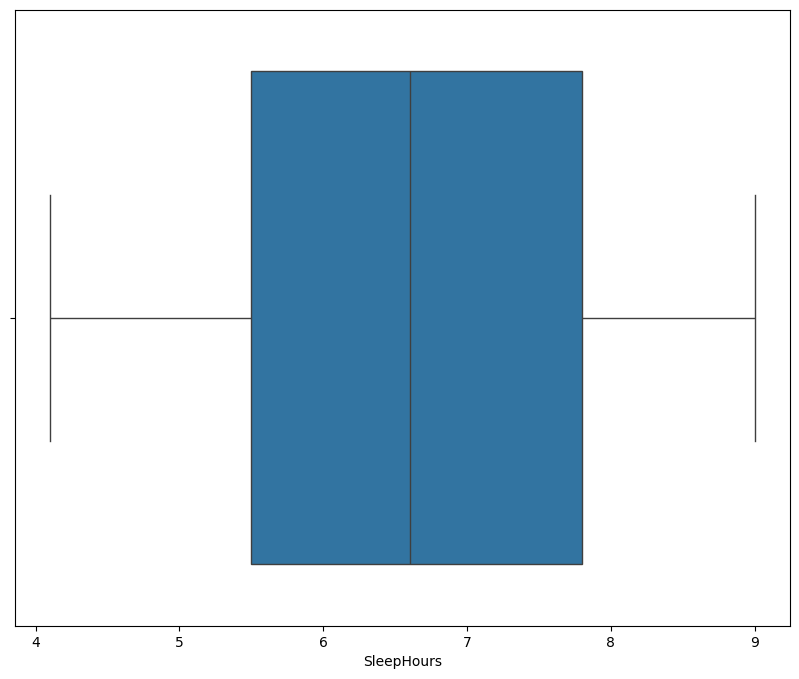

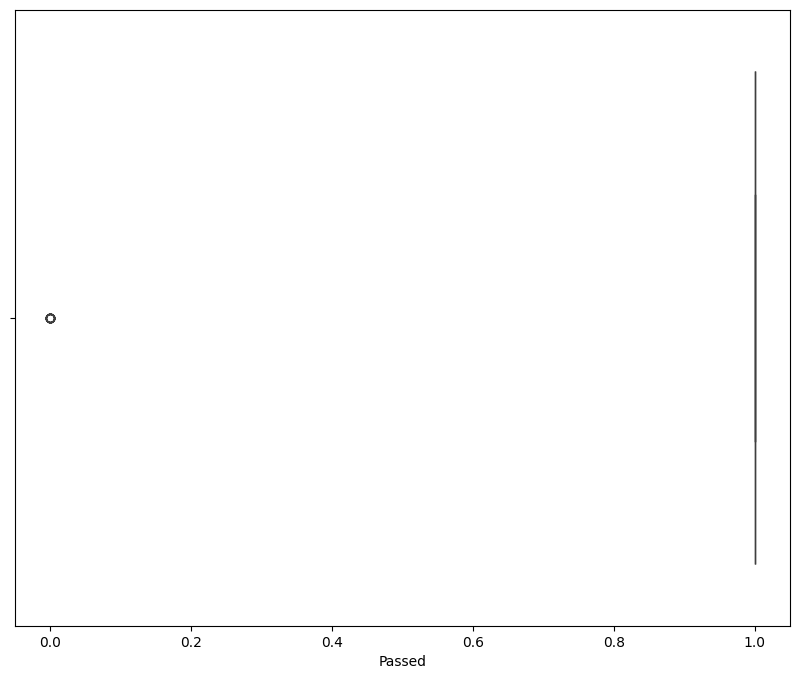

In [21]:
for col in num_col:
  plt.figure(figsize=(10,8))
  sns.boxplot(x = data[col])
  plt.show()

In [28]:
cat_col = data.select_dtypes(include="object").columns

In [32]:
data.head()

,Age,StudyHours,Attendance,PreviousScore,SleepHours,Passed
0,56,1.3,92.7,63.8,6.5,1
1,46,4.0,80.0,60.2,7.7,1
2,32,2.8,89.1,82.1,6.9,1
3,60,8.1,82.2,73.4,9.0,1
4,25,5.0,76.5,83.3,7.8,1


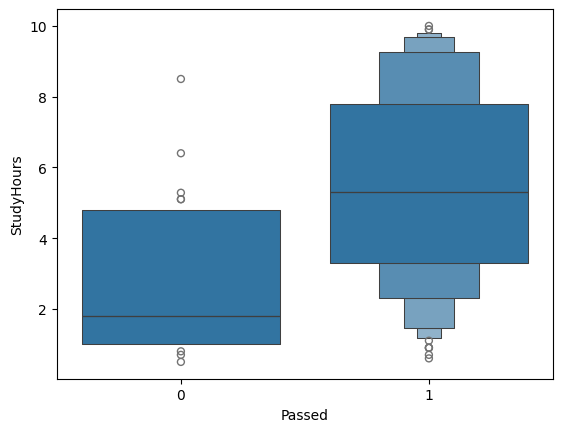

In [33]:
sns.boxenplot(x="Passed", y="StudyHours", data=data)
plt.show()

In [34]:
x = data.drop("Passed",axis=1)
y = data["Passed"]

In [36]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    classification_report,
    precision_score,
    recall_score,
    f1_score,
)

In [37]:
X_train, X_test, y_train, y_test = train_test_split(
    x,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

In [38]:
X_train.shape

(160, 5)

In [39]:
X_test.shape

(40, 5)

In [40]:
X_train.head()

,Age,StudyHours,Attendance,PreviousScore,SleepHours
197,23,6.4,49.9,76.6,8.2
92,52,9.8,83.9,73.9,5.5
138,56,3.6,66.4,77.4,4.7
66,48,5.3,96.2,90.4,4.6
116,54,6.3,62.7,38.1,6.6


In [41]:
numeric_col = ["Age","StudyHours","Attendance","PreviousScore", "SleepHours"]

In [42]:
scaler = StandardScaler()
X_train[numeric_col] = scaler.fit_transform(X_train[numeric_col])
X_test[numeric_col] = scaler.transform(X_test[numeric_col])


In [43]:
X_train.head()

,Age,StudyHours,Attendance,PreviousScore,SleepHours
197,-1.332071,0.376290,-1.482196,0.639768,1.189934
92,1.040601,1.616529,0.745906,0.475001,-0.802513
138,1.367866,-0.645082,-0.400911,0.688588,-1.392868
66,0.713336,-0.024963,1.551954,1.481908,-1.466662
116,1.204233,0.339813,-0.643381,-1.709681,0.009224


In [45]:
model = LogisticRegression(max_iter=1000)
model.fit(X_train,y_train)

LogisticRegression(max_iter=1000)

In [46]:
y_pred = model.predict(X_test)

In [47]:
y_pred

array([1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1])

In [48]:
print("Actual:", y_test.values)
print("Predicted:", y_pred)

Actual: [1 1 1 1 0 1 1 1 0 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 0 1 1 1 1 1 1 1
 0 1 1]
Predicted: [1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 0 1 1 1 1 1 1
 1 1 1]


In [49]:
cm = confusion_matrix(y_test, y_pred)
print("Confusion Matrix:\n", cm)

Confusion Matrix:
 [[ 0  4]
 [ 1 35]]


In [50]:
accuracy = accuracy_score(y_test, y_pred)
print("Accuracy:", accuracy)

Accuracy: 0.875


In [51]:
print("Accuracy :", accuracy_score(y_test, y_pred))
print("Precision:", precision_score(y_test, y_pred))
print("Recall   :", recall_score(y_test, y_pred))
print("F1 Score :", f1_score(y_test, y_pred))

Accuracy : 0.875
Precision: 0.8974358974358975
Recall   : 0.9722222222222222
F1 Score : 0.9333333333333333


In [52]:
from sklearn.neighbors import KNeighborsClassifier
knn = KNeighborsClassifier(n_neighbors=5)
knn.fit(X_train, y_train)

KNeighborsClassifier()

In [53]:
y_pred_knn = knn.predict(X_test)

In [54]:
print("Accuracy :", accuracy_score(y_test, y_pred_knn))
print("Precision:", precision_score(y_test, y_pred_knn))
print("Recall   :", recall_score(y_test, y_pred_knn))
print("F1 Score :", f1_score(y_test, y_pred_knn))

Accuracy : 0.85
Precision: 0.8947368421052632
Recall   : 0.9444444444444444
F1 Score : 0.918918918918919


In [55]:
cm1 = confusion_matrix(y_test, y_pred_knn)
print("Confusion Matrix:\n", cm1)

Confusion Matrix:
 [[ 0  4]
 [ 2 34]]
